# RollBack SMC gaussiano: ESS/systematic e baseline senza resampling

**Notebook autocontenuto per Google Colab.** Carica questo `.ipynb` e scegli **Runtime → Run all**. Non servono altri file, Drive, un language model o GPU. Tutte le funzioni e i test sono incorporati qui.

Il confronto predefinito usa **2.000 run indipendenti per configurazione**, N=2048, dieci configurazioni SMC, con e senza resampling. La durata dipende dalla CPU (alcuni minuti). Le celle salvano dati e grafici nella directory relativa `rollback_smc_results` e mostrano le tabelle. Ridurre RUNS serve solo a una prova rapida, non riproduce l'esperimento consegnato.

Le formule IID della baseline non sono usate come varianza teorica del nuovo algoritmo. La teoria sotto distingue risultati esatti a N finito, implicazioni condizionali di una CLT e inferenza da run complete indipendenti.

In [1]:
# Install only missing runtime dependencies; Colab normally includes all four.
import importlib.util
import subprocess
import sys
required = {"numpy": "numpy>=1.26", "scipy": "scipy>=1.11", "pandas": "pandas>=2.0", "matplotlib": "matplotlib>=3.8"}
missing = [requirement for package, requirement in required.items() if importlib.util.find_spec(package) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink
print({"python": sys.version.split()[0], "numpy": np.__version__, "scipy": scipy.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__})


{'python': '3.14.2', 'numpy': '2.5.1', 'scipy': '1.18.0', 'pandas': '3.0.5', 'matplotlib': '3.11.1'}


# RollBack SMC con ESS e resampling systematic

## Politica effettivamente implementata

Il paper locale *ai4good_rare_event_estimation.tex*, descrizione sperimentale (righe 500–502) e algoritmo nell'appendice (righe 727–744), prescrive:

1. pesatura al nuovo livello;
2. resampling **systematic** se ESS/N < 0.5 e k < R;
3. mutazione RollBack–MH a beta_k, a ogni livello;
4. nessun resampling finale; conservazione dei pesi terminali.

La routine systematic usa un unico offset uniforme, conserva l'ordine di ingresso e produce antenati in ordine crescente, come il codice del paper. Non viene aggiunto sorting per stato né una permutazione. Il toy mantiene T=16, R=8, score x_0, e profondità uniforme in {1,...,D}, D=1,4,16: questi sono i parametri del toy/baseline, non le profondità del decoder linguistico del paper. Non si riproduce qui la media su molte popolazioni con tilt finali diversi: ogni lambda è una configurazione separata che stima lo stesso p.

## Modello e target

Una particella resta la traiettoria completa tau=(x_T,...,x_0), con x_T=0 e Q_t=N(x_t,1/T). La legge originale è

\[
P(d\tau)=\delta_0(dx_T)\prod_{t=T}^{1}Q_t(dx_{t-1}\mid x_t).
\]

Con s(tau)=x_0, h(tau)=1{x_0>=a}, a=Phi^{-1}(0.999), si ha x_0~N(0,1) e p=P(h)=0.001. I target sono

\[
\gamma_k(d\tau)=e^{\beta_k s(\tau)}P(d\tau),\quad
Z_k=e^{\beta_k^2/2},\quad \pi_k=\gamma_k/Z_k.
\]

Pertanto pi_k(A)=1-Phi(a-beta_k), che è diversa dalla probabilità originale p. Conservando (x_T,...,x_d) e rigenerando il suffisso nativo, il rapporto MH è exp{beta_k[s(tau')-s(tau)]}. Il kernel K_k, comprensivo degli sweep, conserva pi_k. Questo non rende indipendenti le particelle dopo resampling né garantisce equilibrio dopo un singolo sweep.

## Ricorrenza dei pesi e del normalizzatore

All'inizio w_0,i=1/N e Zhat_0=1. Prima della mutazione al livello k:

\[
g_{k,i}=G_k(\tau_{k-1,i})=e^{(\beta_k-\beta_{k-1})s(\tau_{k-1,i})},
\quad c_k=\sum_i w_{k-1,i}g_{k,i},
\]
\[
\boxed{\widehat Z_k=\widehat Z_{k-1}c_k,\qquad
\widetilde w_{k,i}=w_{k-1,i}g_{k,i}/c_k.}
\]

ESS_k=1/sum_i tilde(w)_i^2 viene calcolato **dopo** questo aggiornamento. La decisione è J_k=1{ESS_k<0.5N, k<R}.

- Se J_k=0, si conservano gli stati e si pone w_k,i=tilde(w)_k,i.
- Se J_k=1, si estraggono antenati systematic secondo tilde(w), si copiano intere traiettorie e root IDs, si pone w_k,i=1/N.
- In entrambi i casi si applica poi K_k indipendentemente a ciascuna particella selezionata, conservandone il peso.

Zhat_k non è azzerato quando si resampla. Ogni c_k entra nel prodotto, compresi i livelli senza resampling e quello finale. Si usa la scala logaritmica:

\[
\log c_k=\operatorname{logsumexp}_i[\log w_{k-1,i}+\log g_{k,i}],
\quad\log\widehat Z_k=\log\widehat Z_{k-1}+\log c_k.
\]

Senza resampling, Zhat_R=N^{-1}sum_i W_R(H_i), con W_R prodotto dei potenziali valutati prima delle mutazioni. Dopo resampling questa rappresentazione come media di N storie indipendenti **non vale**. La ricorrenza della popolazione è la definizione utilizzata.

## Stimatori

Scriviamo la misura empirica non normalizzata della popolazione

\[
\widehat\Gamma_k^N(f)=\widehat Z_k\sum_iw_{k,i}f(\tau_{k,i}).
\]

Con f_A=e^{-lambda s}h e f_1=e^{-lambda s}, definiamo

\[
U_N=\widehat\Gamma_R^N(f_A),\qquad V_N=\widehat\Gamma_R^N(f_1).
\]

Gli stimatori richiesti sono

\[
\boxed{\widehat p_{\rm ord}=U_N
=\widehat Z_R\sum_iw_{R,i}e^{-\lambda s_i}h_i,}
\]
\[
\boxed{\widehat p_{\rm SN}=U_N/V_N
=\frac{\sum_iw_{R,i}e^{-\lambda s_i}h_i}{\sum_iw_{R,i}e^{-\lambda s_i}}.}
\]

Il fattore Zhat cancella solo nel secondo. Il primo è uno stimatore SMC non normalizzato; chiamarlo IS ordinario non autorizza a trattare le sue particelle come osservazioni IID. V_N è chiamato `reverse_mass` nel codice e ha media esatta 1.

## Perché resampling adattivo systematic conserva la non distorsione

Condizioniamo sulla popolazione al livello k-1, comprendendo tutti i pesi e Zhat. Indichiamo questa informazione con F_{k-1}. Tutti i g_i, c_k, tilde(w)_i e la decisione J_k sono allora noti.

Sia O_i il numero di discendenti del genitore i quando J_k=1. Per systematic,

\[
E[O_i\mid\mathcal F_{k-1}]=N\widetilde w_i.
\]

La proprietà riguarda i conteggi, non l'indipendenza dei discendenti. Per verificarla, sia F_i=sum_{j<=i}tilde(w)_j e U~Unif(0,1); i punti sono (U+j)/N, j=0,...,N-1. Integrando il numero di punti nell'intervallo [F_{i-1},F_i) rispetto a U si ottiene la lunghezza N(F_i-F_{i-1})=N tilde(w)_i.

Se non si resampla,

\[
E[\widehat\Gamma_k^N(f)\mid\mathcal F_{k-1}]
=\widehat Z_k\sum_i\widetilde w_i K_kf(\tau_{k-1,i}).
\]

Se si resampla, prima si condiziona anche sui conteggi O e poi si integra:

\[
\begin{aligned}
E[\widehat\Gamma_k^N(f)\mid\mathcal F_{k-1}]
&=\widehat Z_k E\left[\frac1N\sum_iO_iK_kf(\tau_{k-1,i})\mid\mathcal F_{k-1}\right]\\
&=\widehat Z_k\sum_i\widetilde w_i K_kf(\tau_{k-1,i}).
\end{aligned}
\]

Le due espressioni coincidono. Definendo Q_k f=G_k K_k f,

\[
E[\widehat\Gamma_k^N(f)\mid\mathcal F_{k-1}]
=\widehat\Gamma_{k-1}^N(Q_kf).
\]

Poiché gamma_{k-1}Q_k=gamma_k per l'invarianza di K_k, l'induzione, con particelle iniziali IID da P, dà

\[
E\widehat\Gamma_k^N(f)=\gamma_k(f).
\]

In particolare, per ogni N finito,

\[
\boxed{E\widehat Z_R=Z_R,\quad E U_N=p,\quad E V_N=1.}
\]

La decisione ESS, essendo determinata prima dell'estrazione, non invalida questo argomento. L'ordine input del systematic può cambiare la varianza, ma non questa identità. Non si conclude E(U_N/V_N)=p.

## Decomposizione esatta della varianza per la politica effettiva

Questa è una formula a N finito, non una CLT importata da un'altra politica. Fissata una funzione terminale f_R, costruiamo all'indietro

\[
f_{k-1}=Q_k f_k=G_kK_kf_k,\qquad k=R,\ldots,1.
\]

Definiamo M_k=Gammahat_k^N(f_k). L'identità condizionata precedente implica E[M_k|F_{k-1}]=M_{k-1}. Quindi

\[
M_R-E M_R=(M_0-E M_0)+\sum_{k=1}^R(M_k-M_{k-1}).
\]

Per j<k, l'ortogonalità degli incrementi segue da

\[
E[(M_j-M_{j-1})(M_k-M_{k-1})]
=E[(M_j-M_{j-1})E(M_k-M_{k-1}\mid F_{k-1})]=0.
\]

Anche il termine iniziale è ortogonale agli incrementi successivi. Pertanto

\[
\boxed{\operatorname{Var}(\widehat\Gamma_R^N(f_R))
=\frac{\operatorname{Var}_P(f_0)}{N}
+\sum_{k=1}^R E[\mathcal V_k(f_k)].}
\]

Qui Vcal_k è la varianza condizionata dell'aggiornamento del livello, che ora calcoliamo. Condizionatamente a F_{k-1}, poniamo z=Zhat_k, w_i=tilde(w)_k,i,

\[
m_i=K_kf_k(\tau_{k-1,i}),\qquad
v_i=K_k(f_k^2)(\tau_{k-1,i})-m_i^2.
\]

**Ramo senza resampling.** Le mutazioni sono indipendenti condizionatamente agli stati e ai pesi. Dunque

\[
\boxed{\mathcal V_k^{\rm no}(f_k)=z^2\sum_iw_i^2v_i.}
\]

**Ramo con systematic.** Condizionando prima sui conteggi,

\[
E[M_k\mid O,F_{k-1}]=\frac zN\sum_i O_i m_i,
\quad
\operatorname{Var}(M_k\mid O,F_{k-1})=\frac{z^2}{N^2}\sum_iO_i v_i.
\]

La legge della varianza totale dà

\[
\boxed{\mathcal V_k^{\rm sys}(f_k)
=z^2\left[\frac1N\sum_iw_iv_i
+\frac1{N^2}\sum_{i,j}\operatorname{Cov}_{\rm sys}(O_i,O_j\mid F_{k-1})m_i m_j\right].}
\]

Nella formula complessiva si inserisce

\[
\mathcal V_k=(1-J_k)\mathcal V_k^{\rm no}+J_k\mathcal V_k^{\rm sys},\qquad J_R=0.
\]

La covarianza systematic è definibile esattamente con un integrale monodimensionale. Se O_i(u) sono i conteggi deterministici prodotti dall'offset u,

\[
\operatorname{Cov}_{\rm sys}(O_i,O_j\mid F_{k-1})
=\int_0^1[O_i(u)-Nw_i][O_j(u)-Nw_j]du.
\]

I conteggi sono costanti a tratti; per piccole popolazioni questo integrale si calcola esattamente suddividendo ai punti frac(NF_i). Uno dei test verifica media dei conteggi e formula di varianza condizionata con questa integrazione, e verifica che la matrice non coincida con quella multinomiale.

Per lo stimatore ordinario si prende f_R=f_A. Si ottiene così una formula esatta della sua varianza che incorpora selezione, genealogia e mutazione. Per la varianza di Zhat si prende f_R=1. Non valutiamo numericamente l'intera formula per N=2048: richiederebbe le funzioni backward e le aspettative sulla popolazione, non soltanto momenti di singole traiettorie. Le varianze riportate sono stimate da run complete indipendenti.

## SNIS: cosa è esatto e cosa è soltanto condizionale a una CLT

L'identità esatta è

\[
\widehat p_{\rm SN}-p=\frac{U_N-pV_N}{V_N}.
\]

La decomposizione martingala precedente si può applicare anche a f_R=e^{-lambda s}(h-p). Ne risulta una formula esatta per Var(U_N-pV_N), **non** per Var[(U_N-pV_N)/V_N]. In generale numeratore e denominatore sono dipendenti. Il bias esatto è E[(U_N-pV_N)/V_N], mentre E(U_N-pV_N)=0.

Se si dimostrasse per questa precisa politica una CLT congiunta

\[
\sqrt N\begin{pmatrix}U_N-p\\V_N-1\end{pmatrix}
\Rightarrow\mathcal N(0,\Sigma_{\rm policy}),
\]

allora il metodo delta darebbe coefficienti Sigma_11 per l'ordinario e (1,-p)Sigma(1,-p)^T per SNIS. Questa è un'implicazione condizionale: qui **non dimostriamo tale CLT per systematic non ordinato con soglia ESS fissa**, e non usiamo le formule IID della baseline per predire le nuove varianze. Analogamente, la consistenza SNIS segue se U_N->p e V_N->1; l'unbiasedness a N finito da sola non prova queste convergenze.

Il notebook mostra Var(U_N-pV_N) stimata tra run complete come diagnostica della linearizzazione del rapporto. È chiaramente etichettata come tale: non è un coefficiente CLT dimostrato né una predizione indipendente della varianza SNIS.

## Politiche diverse e limiti dei risultati di letteratura

Se al posto di systematic si usasse multinomial, la covarianza condizionata dei conteggi sarebbe N[diag(w)-ww^T], e il termine con resampling si ridurrebbe a

\[
\mathcal V_k^{\rm multi}=\frac{z^2}{N}\left[\sum_iw_iK_k(f_k^2)(\tau_i)
-\left(\sum_iw_iK_kf_k(\tau_i)\right)^2\right].
\]

Questa semplificazione riguarda **un altro resampler**, non viene applicata al codice o ai risultati. Le formule CLT classiche presentate da Del Moral, Doucet e Jasra (2006, sezione 3.3.2) considerano esplicitamente resampling multinomiale nei casi mai/sempre. [Articolo originale](https://www.cs.ubc.ca/~arnaud/delmoral_doucet_jasra_sequentialmontecarlosamplersJRSSB.pdf).

Per il resampling adattivo, Del Moral, Doucet e Jasra (2012) sviluppano risultati tramite una politica limite; la coincidenza del criterio limite con la soglia è un caso delicato. Le ipotesi su schema di selezione, separazione dalla soglia e funzioni non limitate vanno verificate: non basta usare ESS per invocare il teorema. [Articolo originale](https://www.stats.ox.ac.uk/~doucet/delmoral_doucet_jasra_adaptiveresamplingSMC.pdf).

Gerber, Chopin e Whiteley mostrano che la convergenza del systematic può dipendere dall'ordine degli input e che non esiste una garanzia universale per ordinamenti arbitrari. Questo non dimostra che il toy implementato sia inconsistente; impedisce però di trasferire automaticamente un teorema per altri resampler. [Articolo originale](https://arxiv.org/abs/1707.01845).

## Inferenza legittima tra run complete

Con N fissato, B esecuzioni indipendenti producono B stime IID Y_b dell'intero algoritmo. Quindi media, varianza campionaria e RMSE tra queste run sono strumenti validi senza supporre indipendenza delle particelle interne:

\[
\bar Y=B^{-1}\sum_bY_b,\quad
s_Y^2=(B-1)^{-1}\sum_b(Y_b-\bar Y)^2,\quad
\widehat{\rm RMSE}=\sqrt{B^{-1}\sum_b(Y_b-p)^2}.
\]

SE della media è s_Y/sqrt(B). Una CLT in **B**, a N fissato, riguarda la media delle run e ha centro E(Y_b): per l'ordinario è p, per SNIS può differire da p. L'errore Monte Carlo della varianza viene stimato dalla dispersione dei quadrati centrati tra run. Queste approssimazioni possono risentire di code pesanti e non sono intervalli simultanei.

Il codice registra per ogni run ESS a tutti i livelli, decisioni di resampling, log-incrementi, Zhat, reverse_mass, transizioni gaussiane incluse le proposal rifiutate, tempo e antenati distinti. Il confronto principale resta a N uguale; il prodotto varianza per costo in transizioni è un indicatore aggiuntivo, non un esperimento a budget abbinato.

## Funzioni complete: modello, RollBack–MH, resampling e stimatori

In `run_smc`, i commenti **PAPER STEP 1/2/3** individuano pesatura, soglia ESS con esclusione finale, e mutazione. La riga `log_z += log_c` è esterna al ramo di resampling e viene eseguita sempre.

In [2]:
"""Gaussian full-path RollBack SMC: paper-faithful ESS/systematic policy.

This file is also embedded verbatim in the standalone Colab notebook.
Arrays store [x_T, ..., x_0]. No language model and no direct tilted sampling.
"""
from dataclasses import dataclass
import numpy as np
from scipy.special import logsumexp
from scipy.stats import norm

P_EVENT = 0.001
THRESHOLD = float(norm.isf(P_EVENT))


@dataclass(frozen=True)
class Config:
    steps: int = 16
    levels: int = 8
    tilt: float = 2.0
    max_depth: int = 16
    sweeps: int = 1
    ess_threshold: float = 0.5

    def __post_init__(self):
        if self.steps < 1 or self.levels < 1 or self.sweeps < 0:
            raise ValueError("Invalid steps, levels or sweeps")
        if not 1 <= self.max_depth <= self.steps or not np.isfinite(self.tilt) or self.tilt < 0:
            raise ValueError("Invalid rollback depth or tilt")
        if not 0 <= self.ess_threshold <= 1:
            raise ValueError("ESS threshold must be in [0,1]")


def base_paths(rng, n, steps):
    paths = np.zeros((n, steps + 1))
    paths[:, 1:] = np.cumsum(rng.normal(0, 1 / np.sqrt(steps), (n, steps)), axis=1)
    return paths


def rollback_proposal(rng, paths, max_depth):
    n, columns = paths.shape
    steps = columns - 1
    depths = rng.integers(1, max_depth + 1, n)
    proposed = paths.copy()
    for depth in range(1, max_depth + 1):
        rows = np.flatnonzero(depths == depth)
        start = steps - depth
        noise = rng.normal(0, 1 / np.sqrt(steps), (len(rows), depth))
        proposed[rows, start + 1:] = paths[rows, start, None] + np.cumsum(noise, axis=1)
    return proposed, depths


def rollback_mh(rng, paths, beta, max_depth):
    proposed, depths = rollback_proposal(rng, paths, max_depth)
    log_alpha = np.minimum(0.0, beta * (proposed[:, -1] - paths[:, -1]))
    accept = np.log(rng.random(len(paths))) < log_alpha
    paths[accept] = proposed[accept]
    return int(accept.sum()), int(depths.sum())


def systematic_resample(rng, normalized_weights):
    """One common uniform offset; preserve input order, as in paper code.

    The offspring are NOT independent categorical draws.
    """
    weights = np.asarray(normalized_weights, dtype=float)
    if weights.ndim != 1 or len(weights) == 0 or np.any(weights < 0):
        raise ValueError("Invalid weights")
    if not np.isclose(weights.sum(), 1.0):
        raise ValueError("Weights must be normalized")
    n = len(weights)
    cumulative = np.cumsum(weights)
    cumulative[-1] = 1.0
    points = (rng.random() + np.arange(n)) / n
    return np.searchsorted(cumulative, points, side="left")


@dataclass
class SMCResult:
    paths: np.ndarray
    log_weights: np.ndarray  # normalized terminal weights
    log_z: float
    levels: list
    transitions: int
    accepted: int
    proposals: int
    roots: np.ndarray
    trace: list | None = None

    def estimates(self, tilt):
        reverse_log_weights = self.log_weights - tilt * self.paths[:, -1]
        event = self.paths[:, -1] >= THRESHOLD
        log_num = logsumexp(reverse_log_weights[event]) if event.any() else -np.inf
        log_den = logsumexp(reverse_log_weights)
        return {"ordinary": float(np.exp(self.log_z + log_num)),
                "snis": float(np.exp(log_num - log_den)),
                "reverse_mass": float(np.exp(self.log_z + log_den)),
                "z_hat": float(np.exp(self.log_z))}


def run_smc(rng, n, config, resampling=True, trace=False, initial_paths=None):
    """Order is weighting -> conditional systematic resampling -> MH.

    The normalizer is updated at EVERY level, not only at resampling times.
    Initial paths can be supplied for deterministic branch tests only.
    """
    if n < 1:
        raise ValueError("n must be positive")
    if initial_paths is None:
        paths = base_paths(rng, n, config.steps)
        transitions = n * config.steps
    else:
        paths = np.array(initial_paths, dtype=float, copy=True)
        if paths.shape != (n, config.steps + 1) or not np.all(paths[:, 0] == 0):
            raise ValueError("Invalid initial trajectories")
        transitions = 0
    log_w = np.full(n, -np.log(n))
    log_z = 0.0
    roots = np.arange(n)
    accepted = proposals = 0
    history, full_trace = [], [] if trace else None
    schedule = np.linspace(0.0, config.tilt, config.levels + 1)
    for k, (old_beta, beta) in enumerate(zip(schedule[:-1], schedule[1:]), start=1):
        if trace:
            before = paths.copy()
            old_log_w, old_log_z = log_w.copy(), log_z
        # PAPER STEP 1: weight BEFORE mutation. log_w is already normalized.
        unnormalized = log_w + (beta - old_beta) * paths[:, -1]
        log_c = float(logsumexp(unnormalized))
        log_z += log_c  # EVERY LEVEL, regardless of the resampling decision.
        log_w = unnormalized - log_c
        ess_before = float(np.exp(-logsumexp(2 * log_w)))
        # PAPER STEP 2: strict ESS/N < 0.5; explicitly EXCLUDE final level.
        do_resample = bool(resampling and k < config.levels and ess_before < config.ess_threshold * n)
        parents = None
        if do_resample:
            parents = systematic_resample(rng, np.exp(log_w))
            paths = paths[parents].copy()  # copy COMPLETE stored trajectories
            roots = roots[parents].copy()
            log_w.fill(-np.log(n))
            # Do NOT reset log_z here.
        ess_after = float(np.exp(-logsumexp(2 * log_w)))
        if trace:
            after_selection = paths.copy()
        # PAPER STEP 3: mutate at beta_k at EVERY level, including final.
        stage_cost = stage_accepted = 0
        for _ in range(config.sweeps):
            moves, cost = rollback_mh(rng, paths, beta, config.max_depth)
            stage_accepted += moves
            stage_cost += cost
            proposals += n
        accepted += stage_accepted
        transitions += stage_cost
        history.append({"level": k, "beta": float(beta), "ess_before": ess_before,
                        "ess_after": ess_after, "resampled": do_resample,
                        "log_c": log_c, "log_z": float(log_z), "z_hat": float(np.exp(log_z)),
                        "transitions_stage": stage_cost, "transitions_cumulative": transitions,
                        "accepted": stage_accepted, "distinct_roots": int(np.unique(roots).size)})
        if trace:
            full_trace.append({"before": before, "old_log_w": old_log_w, "old_log_z": old_log_z,
                               "parents": parents, "after_selection": after_selection,
                               "after_mutation": paths.copy(), "log_w": log_w.copy()})
    return SMCResult(paths, log_w, log_z, history, transitions, accepted, proposals, roots, full_trace)


def run_independent_baseline(rng, n, config):
    """Original no-resampling algorithm, implemented through path weights.

    Kept independent of run_smc to check the two normalizer calculations.
    Same base-path and MH random draws as the original delivered baseline.
    """
    paths = base_paths(rng, n, config.steps)
    log_raw = np.zeros(n)
    transitions = n * config.steps
    accepted = proposals = 0
    history = []
    old_log_z = 0.0
    schedule = np.linspace(0.0, config.tilt, config.levels + 1)
    for k, (old_beta, beta) in enumerate(zip(schedule[:-1], schedule[1:]), start=1):
        log_raw += (beta-old_beta) * paths[:, -1]
        log_z = float(logsumexp(log_raw)-np.log(n))
        log_w = log_raw-logsumexp(log_raw)
        ess = float(np.exp(-logsumexp(2*log_w)))
        stage_cost = stage_accepted = 0
        for _ in range(config.sweeps):
            moves, cost = rollback_mh(rng, paths, beta, config.max_depth)
            stage_accepted += moves
            stage_cost += cost
            proposals += n
        accepted += stage_accepted
        transitions += stage_cost
        history.append({"level": k, "beta": float(beta), "ess_before": ess, "ess_after": ess,
                        "resampled": False, "log_c": log_z-old_log_z, "log_z": log_z,
                        "z_hat": float(np.exp(log_z)), "transitions_stage": stage_cost,
                        "transitions_cumulative": transitions, "accepted": stage_accepted,
                        "distinct_roots": n})
        old_log_z = log_z
    return SMCResult(paths, log_w, log_z, history, transitions, accepted, proposals, np.arange(n))


## Test mirati

I test includono entrambi i rami ESS, una popolazione concentrata che forza il resampling, e il divieto finale anche sotto soglia. Il test systematic integra esattamente i conteggi su tutti gli intervalli dell'offset. Le estrazioni tilted dirette compaiono solo nel test di invarianza.

In [3]:
"""Assertions embedded in the notebook; no local imports are required there."""
import numpy as np
from scipy.special import logsumexp


def run_checks():
    checks = []

    def passed(name):
        checks.append(name)
        print("PASS:", name)

    def close_mc(values, expected, tolerance=7):
        values = np.asarray(values)
        error = values.std(ddof=1)/np.sqrt(values.size)
        assert abs(values.mean()-expected) <= tolerance*error + 1e-12

    rng = np.random.default_rng(71001)
    paths = base_paths(rng, 150_000, 16)
    close_mc(paths[:, -1], 0)
    close_mc(paths[:, -1]**2, 1)
    close_mc((paths[:, -1] >= THRESHOLD).astype(float), P_EVENT)
    assert np.all(paths[:, 0] == 0)
    passed("original terminal law N(0,1)")

    proposed, depths = rollback_proposal(rng, paths[:30_000], 16)
    for d in range(1, 17):
        rows = depths == d
        np.testing.assert_array_equal(proposed[rows, :17-d], paths[:30_000][rows, :17-d])
        close_mc(rows.astype(float), 1/16)
    passed("uniform depth and complete conserved prefix")

    beta = 2.0
    # Exact tilted draws are solely an invariance TEST, not the SMC sampler.
    stationary = base_paths(rng, 100_000, 16) + beta*np.arange(17)[None, :]/16
    for _ in range(3):
        rollback_mh(rng, stationary, beta, 16)
    for j in (4, 8, 16):
        centered = stationary[:, j]-beta*j/16
        close_mc(centered, 0)
        close_mc(centered**2, j/16)
    close_mc((stationary[:, 4]-beta/4)*(stationary[:, -1]-beta), .25)
    passed("MH invariance of path moments and covariance")

    cfg = Config(tilt=2.0)
    seed = 71002
    disabled = run_smc(np.random.default_rng(seed), 2048, cfg, resampling=False)
    baseline = run_independent_baseline(np.random.default_rng(seed), 2048, cfg)
    np.testing.assert_array_equal(disabled.paths, baseline.paths)
    np.testing.assert_allclose(disabled.log_weights, baseline.log_weights, atol=1e-13)
    np.testing.assert_allclose(disabled.log_z, baseline.log_z, atol=1e-13)
    for key, value in baseline.estimates(cfg.tilt).items():
        np.testing.assert_allclose(disabled.estimates(cfg.tilt)[key], value, atol=1e-13)
    assert not any(s["resampled"] for s in disabled.levels)
    passed("disabled branch exactly reproduces independent path-weight baseline")

    zero = run_smc(np.random.default_rng(71003), 4096, Config(tilt=0))
    assert not any(s["resampled"] for s in zero.levels)
    np.testing.assert_allclose(zero.estimates(0)["z_hat"], 1)
    mc = np.mean(zero.paths[:, -1] >= THRESHOLD)
    np.testing.assert_allclose(zero.estimates(0)["ordinary"], mc)
    np.testing.assert_allclose(zero.estimates(0)["snis"], mc)
    passed("ESS policy genuinely skips resampling at zero tilt")

    # Deterministic concentrated population guarantees ESS/N < 0.5.
    initial = np.zeros((4, 3))
    initial[3] = [0, 5, 10]
    branch = run_smc(np.random.default_rng(71004), 4,
                     Config(steps=2, levels=3, tilt=1, max_depth=2, sweeps=0),
                     initial_paths=initial, trace=True)
    assert branch.levels[0]["ess_before"] < 2
    assert branch.levels[0]["resampled"]
    assert any(not row["resampled"] for row in branch.levels)
    for row, tr in zip(branch.levels, branch.trace):
        if row["resampled"]:
            np.testing.assert_array_equal(tr["after_selection"], tr["before"][tr["parents"]])
            np.testing.assert_allclose(tr["log_w"], -np.log(4))
            np.testing.assert_allclose(row["ess_after"], 4)
    passed("active ESS branch copies full paths and resets only particle weights")

    for row, tr in zip(branch.levels, branch.trace):
        expected_increment = logsumexp(tr["old_log_w"] + (1/3)*tr["before"][:, -1])
        np.testing.assert_allclose(row["log_c"], expected_increment)
        np.testing.assert_allclose(row["log_z"], tr["old_log_z"]+expected_increment)
    np.testing.assert_allclose(branch.log_z, sum(r["log_c"] for r in branch.levels))
    nonresampling_increments = [r["log_c"] for r in branch.levels if not r["resampled"]]
    assert any(abs(x) > .1 for x in nonresampling_increments)
    passed("Z_hat includes non-resampling levels and is never reset")

    final = run_smc(np.random.default_rng(71005), 4,
                   Config(steps=2, levels=1, tilt=1, max_depth=2, sweeps=0),
                   initial_paths=initial, trace=True)
    assert final.levels[0]["ess_before"] < 2
    assert not final.levels[0]["resampled"]
    assert np.exp(final.log_weights).max() > .99
    np.testing.assert_allclose(np.exp(final.log_z), np.exp(initial[:, -1]).mean())
    passed("final resampling excluded even when final ESS is below threshold")

    moving = run_smc(np.random.default_rng(71006), 128, Config(tilt=3), trace=True)
    old_beta = 0
    for row, tr in zip(moving.levels, moving.trace):
        increment = logsumexp(tr["old_log_w"]+(row["beta"]-old_beta)*tr["before"][:, -1])
        np.testing.assert_allclose(increment, row["log_c"])
        old_beta = row["beta"]
    assert not np.array_equal(moving.trace[-1]["after_selection"], moving.paths)
    assert moving.transitions == 128*16 + sum(s["transitions_stage"] for s in moving.levels)
    assert 128*8 <= moving.transitions-128*16 <= 128*8*16
    assert moving.proposals == 128*8
    passed("weight-before-move order, final mutation and exact Gaussian cost")

    weights = np.exp(moving.log_weights)
    inverse = np.exp(-3*moving.paths[:, -1])
    h = moving.paths[:, -1] >= THRESHOLD
    estimates = moving.estimates(3)
    np.testing.assert_allclose(estimates["ordinary"], np.exp(moving.log_z)*np.sum(weights*inverse*h))
    np.testing.assert_allclose(estimates["snis"], np.sum(weights*inverse*h)/np.sum(weights*inverse))
    np.testing.assert_allclose(estimates["reverse_mass"], np.exp(moving.log_z)*np.sum(weights*inverse))
    passed("both requested estimators use normalized terminal weights and Z_hat")

    class FixedOffset:
        def __init__(self, offset):
            self.offset = offset
        def random(self):
            return self.offset

    # Integrate exactly over offset intervals; counts constant within intervals.
    weights = np.array([.05, .15, .3, .5])
    n = len(weights)
    knots = np.unique(np.r_[0, np.mod(n*np.cumsum(weights), 1), 1])
    counts, probabilities = [], []
    for left, right in zip(knots[:-1], knots[1:]):
        parents = systematic_resample(FixedOffset((left+right)/2), weights)
        counts.append(np.bincount(parents, minlength=n))
        probabilities.append(right-left)
    counts, probabilities = np.array(counts), np.array(probabilities)
    np.testing.assert_allclose(probabilities@counts, n*weights, atol=1e-14)
    centered = counts-n*weights
    covariance = (centered.T*probabilities)@centered
    multinomial_covariance = n*(np.diag(weights)-np.outer(weights, weights))
    assert not np.allclose(covariance, multinomial_covariance)
    # Conditional variance formula for resampling followed by independent moves.
    means, variances = np.array([1., -2., 4., 0.]), np.array([.1, .2, .3, .4])
    total_var_direct = probabilities@((counts@variances)/n**2 + (counts@means/n-weights@means)**2)
    total_var_formula = weights@variances/n + means@covariance@means/n**2
    np.testing.assert_allclose(total_var_direct, total_var_formula)
    passed("systematic offspring unbiasedness and correct conditional covariance")

    estimates, active_runs = [], 0
    cfg = Config(steps=4, levels=4, tilt=2, max_depth=4)
    for rep in range(500):
        result = run_smc(np.random.default_rng(np.random.SeedSequence([71007, rep])), 512, cfg)
        estimates.append(result.estimates(cfg.tilt))
        active_runs += any(r["resampled"] for r in result.levels)
    assert active_runs > 100
    close_mc([r["ordinary"] for r in estimates], P_EVENT)
    close_mc([r["reverse_mass"] for r in estimates], 1)
    close_mc([r["z_hat"] for r in estimates], np.exp(2))
    passed("whole-population identities E[p_ord]=p, E[reverse_mass]=1, E[Z_hat]=Z with active resampling")
    return checks



In [4]:
passed_checks = run_checks()
assert len(passed_checks) == 12
print(f'Completati {len(passed_checks)} controlli.')

PASS: original terminal law N(0,1)
PASS: uniform depth and complete conserved prefix
PASS: MH invariance of path moments and covariance
PASS: disabled branch exactly reproduces independent path-weight baseline
PASS: ESS policy genuinely skips resampling at zero tilt
PASS: active ESS branch copies full paths and resets only particle weights
PASS: Z_hat includes non-resampling levels and is never reset
PASS: final resampling excluded even when final ESS is below threshold
PASS: weight-before-move order, final mutation and exact Gaussian cost
PASS: both requested estimators use normalized terminal weights and Z_hat
PASS: systematic offspring unbiasedness and correct conditional covariance


PASS: whole-population identities E[p_ord]=p, E[reverse_mass]=1, E[Z_hat]=Z with active resampling
Completati 12 controlli.


## Parametri riproducibili

T=16, R=8, una mutazione per livello, schedule lineare. Profondità uniforme su {1,...,D}; soglia ESS/N < 0.5; systematic in ordine input; mai resampling finale. Seed separati per crude MC (stream 0), baseline (stream 1) e algoritmo con resampling (stream 4). La baseline ricostruisce gli stessi contributi e seed del lavoro precedente, senza leggere i suoi file.

In [5]:
N = 2048
RUNS = 2000
ROOT_SEED = 20260929
OUTPUT_DIR = 'rollback_smc_results'

## Una run leggibile: ESS, resampling e normalizzatore a ogni livello

In [6]:
demo_config = Config(tilt=3, max_depth=16)
demo = run_smc(np.random.default_rng(71008), 256, demo_config)
assert any(row['resampled'] for row in demo.levels)
assert not demo.levels[-1]['resampled']
display(pd.DataFrame(demo.levels)[['level', 'beta', 'ess_before', 'ess_after', 'resampled', 'log_c', 'z_hat', 'transitions_cumulative']])
print('Stime della run dimostrativa:', demo.estimates(demo_config.tilt))


,level,beta,ess_before,ess_after,resampled,log_c,z_hat,transitions_cumulative
0,1,0.375,220.148133,220.148133,False,0.073552,1.076325,6377
1,2,0.750,155.013859,155.013859,False,0.226870,1.350429,8603
2,3,1.125,96.176761,256.000000,True,0.334664,1.887184,10783
3,4,1.500,223.659928,223.659928,False,0.478388,3.044916,12881
4,5,1.875,158.766366,158.766366,False,0.630579,5.720481,15079
5,6,2.250,104.615465,256.000000,True,0.765824,12.303412,17399
6,7,2.625,236.294093,236.294093,False,0.874505,29.499731,19498
7,8,3.000,200.934178,200.934178,False,0.947709,76.103176,21545


Stime della run dimostrativa: {'ordinary': 0.0007992246176656004, 'snis': 0.0017161028845085302, 'reverse_mass': 0.46572068894021357, 'z_hat': 76.10317628778235}


## Esperimenti e report: funzioni incorporate

Le varianze sono calcolate sulle stime finali di run indipendenti dell'intera popolazione. Non si usa l'ESS come sostituto della varianza, né si trattano i discendenti come IID.

In [7]:
"""Whole-algorithm independent runs; also embedded in the Colab notebook."""
import json
import time
import platform
from pathlib import Path
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy


def population_row(result, config, policy, cid, rep, seed, seconds):
    estimates = result.estimates(config.tilt)
    return {"config_id": cid, "lambda": config.tilt, "D": config.max_depth,
            "policy": policy, "replicate": rep, "seed": json.dumps(seed), **estimates,
            "log_z": result.log_z, "seconds": seconds, "transitions": result.transitions,
            "acceptance": result.accepted/result.proposals if result.proposals else 0,
            "distinct_roots": int(np.unique(result.roots).size),
            "tilted_probability_estimate": float(np.sum(np.exp(result.log_weights)*(result.paths[:, -1] >= THRESHOLD))),
            "resampling_count": sum(s["resampled"] for s in result.levels),
            "resampled_levels": json.dumps([s["level"] for s in result.levels if s["resampled"]]),
            "ess_before": json.dumps([s["ess_before"] for s in result.levels]),
            "ess_after": json.dumps([s["ess_after"] for s in result.levels]),
            "log_c_path": json.dumps([s["log_c"] for s in result.levels]),
            "log_z_path": json.dumps([s["log_z"] for s in result.levels]),
            "stage_transitions": json.dumps([s["transitions_stage"] for s in result.levels])}


def summarize_runs(frame, n, steps):
    summaries = []
    for (cid, policy), group in frame.groupby(["config_id", "policy"], sort=True):
        if policy == "crude":
            estimators = ["ordinary"]
        else:
            estimators = ["ordinary", "snis"]
        for estimator in estimators:
            values = group[estimator].to_numpy()
            b = len(values)
            variance = values.var(ddof=1)
            bias = values.mean()-P_EVENT
            summaries.append({"config_id": cid, "lambda": group["lambda"].iloc[0],
                              "D": group["D"].iloc[0], "policy": policy, "estimator": estimator,
                              "N": n, "runs": b, "mean": values.mean(), "bias": bias,
                              "bias_mc_se": np.sqrt(variance/b), "variance": variance,
                              "variance_mc_se": ((values-values.mean())**2).std(ddof=1)/np.sqrt(b),
                              "rmse": np.sqrt(np.mean((values-P_EVENT)**2)),
                              "zero_frequency": np.mean(values == 0), "median_seconds": group.seconds.median(),
                              "mean_transitions": group.transitions.mean(),
                              "variance_times_cost_relative_mc": variance*group.transitions.mean()/(P_EVENT*(1-P_EVENT)*steps),
                              "mse_times_cost_relative_mc": np.mean((values-P_EVENT)**2)*group.transitions.mean()/(P_EVENT*(1-P_EVENT)*steps),
                              "resampling_run_fraction": np.mean(group.resampling_count > 0),
                              "mean_resampling_count": group.resampling_count.mean(),
                              "mean_z_hat": group.z_hat.mean(), "z_hat_mc_se": group.z_hat.std(ddof=1)/np.sqrt(b),
                              "true_z": np.exp(float(group["lambda"].iloc[0])**2/2),
                              "mean_reverse_mass": group.reverse_mass.mean(),
                              "reverse_mass_mc_se": group.reverse_mass.std(ddof=1)/np.sqrt(b),
                              # A diagnostic using complete independent runs, not an IID-particle CLT.
                              "whole_run_linearization_variance": np.var(group.ordinary-P_EVENT*group.reverse_mass, ddof=1)})
    return pd.DataFrame(summaries)


def run_comparison(n=2048, runs=2000, root_seed=20260929, output_dir="rollback_smc_results"):
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    configs = [Config(tilt=0, max_depth=16)] + [Config(tilt=lam, max_depth=d) for d in (1, 4, 16) for lam in (1, 2, 3)]
    manifest = {"N": n, "runs": runs, "root_seed": root_seed, "p": P_EVENT, "a": THRESHOLD,
                "configs": [asdict(c) for c in configs], "resampler": "systematic, one common uniform offset, input order retained",
                "trigger": "ESS/N < 0.5 and k < R", "order": "weight -> resample if triggered -> MH at new beta",
                "final_resampling": False, "seed_scheme": "SeedSequence([root_seed, stream, config_id, replicate])",
                "streams": {"crude": 0, "independent_baseline": 1, "ess_systematic": 4},
                "python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
                "pandas": pd.__version__, "variance_method": "sample variance across independent complete algorithm runs; no IID-particle CLT for resampling"}
    started = time.perf_counter()
    rows = []
    for rep in range(runs):
        seed = [root_seed, 0, 0, rep]
        rng = np.random.default_rng(np.random.SeedSequence(seed))
        now = time.perf_counter()
        paths = base_paths(rng, n, 16)
        value = float(np.mean(paths[:, -1] >= THRESHOLD))
        seconds = time.perf_counter()-now
        rows.append({"config_id": -1, "lambda": 0, "D": 0, "policy": "crude", "replicate": rep,
                     "seed": json.dumps(seed), "ordinary": value, "snis": value, "reverse_mass": 1.,
                     "z_hat": 1., "log_z": 0., "seconds": seconds, "transitions": n*16,
                     "acceptance": 0., "distinct_roots": n, "tilted_probability_estimate": value,
                     "resampling_count": 0, "resampled_levels": "[]", "ess_before": "[]", "ess_after": "[]",
                     "log_c_path": "[]", "log_z_path": "[]", "stage_transitions": "[]"})
    print(f"Crude MC: {runs} run complete", flush=True)
    for cid, cfg in enumerate(configs):
        for policy, stream in (("independent", 1), ("ess_systematic", 4)):
            for rep in range(runs):
                seed = [root_seed, stream, cid, rep]
                rng = np.random.default_rng(np.random.SeedSequence(seed))
                now = time.perf_counter()
                if policy == "independent":
                    result = run_independent_baseline(rng, n, cfg)
                else:
                    result = run_smc(rng, n, cfg)
                estimates = result.estimates(cfg.tilt)
                seconds = time.perf_counter()-now
                assert np.isfinite(estimates["ordinary"]) and np.isfinite(estimates["snis"])
                assert not result.levels[-1]["resampled"]
                rows.append(population_row(result, cfg, policy, cid, rep, seed, seconds))
            pd.DataFrame(rows).to_csv(out / "runs.csv", index=False)
            print(f"lambda={cfg.tilt:g}, D={cfg.max_depth}, {policy}: {runs} run; elapsed {time.perf_counter()-started:.1f}s", flush=True)
    frame = pd.DataFrame(rows)
    summary = summarize_runs(frame, n, 16)
    summary.to_csv(out / "summary.csv", index=False)
    # Not sufficient to run a dormant ESS policy: require actual activation.
    active = frame.query("policy == 'ess_systematic' and resampling_count > 0")
    assert len(active) > 0, "Experiment invalid: resampling never activated"
    assert not any(8 in json.loads(v) for v in frame.resampled_levels)
    for _, row in frame.query("policy != 'crude'").iterrows():
        np.testing.assert_allclose(sum(json.loads(row.log_c_path)), row.log_z, atol=1e-11)
        assert row.transitions == n*16 + sum(json.loads(row.stage_transitions))
    manifest["active_resampling_runs"] = len(active)
    manifest["simulation_and_export_seconds"] = time.perf_counter()-started
    (out / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"Resampling realmente attivo in {len(active)} run; mai al livello finale.")
    return frame, summary, manifest


def create_figures(frame, summary, manifest, output_dir="rollback_smc_results"):
    out = Path(output_dir)
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
    n = manifest["N"]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
    colors = {"ordinary": "#176b8c", "snis": "#b94b32"}
    for ax, depth in zip(axes, (1, 4, 16)):
        for policy, style in (("independent", "--"), ("ess_systematic", "-")):
            for estimator in ("ordinary", "snis"):
                g = summary.query("D == @depth and policy == @policy and estimator == @estimator and `lambda` > 0").sort_values("lambda")
                ax.errorbar(g["lambda"], g.variance, yerr=1.96*g.variance_mc_se, linestyle=style,
                            marker="o" if estimator == "ordinary" else "s", color=colors[estimator],
                            capsize=2, label=f"{policy}: {estimator}")
        ax.axhline(P_EVENT*(1-P_EVENT)/n, color="gray", linestyle=":", label="Crude MC: exact")
        ax.set(title=f"Uniform rollback depth 1,...,{depth}", xlabel="lambda", yscale="log", xticks=[1, 2, 3])
        ax.grid(alpha=.2)
    axes[0].set_ylabel("Variance across independent full runs")
    axes[-1].legend(fontsize=7)
    fig.suptitle("ESS systematic vs independent baseline — empirical variances, not an IID-particle CLT")
    fig.tight_layout()
    fig.savefig(out / "variance_comparison.png", dpi=160)
    plt.show()
    plt.close(fig)

    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
    levels = np.arange(1, 9)
    for col, depth in enumerate((1, 4, 16)):
        for tilt, color in zip((1, 2, 3), ("#176b8c", "#b94b32", "#5b4594")):
            g = frame.query("D == @depth and `lambda` == @tilt and policy == 'ess_systematic'")
            ess = np.array([json.loads(v) for v in g.ess_before])/n
            activation = np.array([[k in json.loads(v) for k in levels] for v in g.resampled_levels])
            axes[0, col].plot(levels, ess.mean(axis=0), "o-", color=color, label=f"lambda={tilt}")
            axes[0, col].fill_between(levels, np.quantile(ess, .1, axis=0), np.quantile(ess, .9, axis=0), color=color, alpha=.12)
            axes[1, col].plot(levels, activation.mean(axis=0), "o-", color=color)
        axes[0, col].axhline(.5, color="black", linestyle=":")
        axes[0, col].set(title=f"D={depth}", ylim=(0, 1.05))
        axes[1, col].set(xlabel="SMC level k", ylim=(-.03, 1.03), xticks=levels)
        axes[0, col].grid(alpha=.2)
        axes[1, col].grid(alpha=.2)
    axes[0, 0].set_ylabel("ESS/N before resampling (mean, 10–90%)")
    axes[1, 0].set_ylabel("Fraction of runs resampling at level k")
    axes[0, -1].legend()
    fig.suptitle("The ESS branch activates; the final level never resamples")
    fig.tight_layout()
    fig.savefig(out / "resampling_diagnostics.png", dpi=160)
    plt.show()
    plt.close(fig)

    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for depth, style in ((1, ":"), (4, "--"), (16, "-")):
        for estimator in ("ordinary", "snis"):
            g = summary.query("policy == 'ess_systematic' and D == @depth and estimator == @estimator and `lambda` > 0").sort_values("lambda")
            options = dict(color=colors[estimator], linestyle=style, marker="o" if estimator == "ordinary" else "s", label=f"{estimator}, D={depth}")
            axes[0, 0].errorbar(g["lambda"], g.bias/P_EVENT, yerr=1.96*g.bias_mc_se/P_EVENT, capsize=2, **options)
            axes[0, 1].plot(g["lambda"], g.rmse/P_EVENT, **options)
            axes[1, 0].plot(g["lambda"], g.zero_frequency, **options)
            axes[1, 1].plot(g["lambda"], g.mse_times_cost_relative_mc, **options)
    axes[0, 0].axhline(0, color="gray", linestyle=":")
    axes[0, 1].axhline(np.sqrt(P_EVENT*(1-P_EVENT)/n)/P_EVENT, color="gray", linestyle=":")
    axes[1, 0].axhline((1-P_EVENT)**n, color="gray", linestyle=":")
    axes[1, 1].axhline(1, color="gray", linestyle=":")
    for ax, title in zip(axes.flat, ("Relative bias (Monte Carlo uncertainty)", "Relative RMSE", "Zero-estimate frequency", "MSE × transitions / crude MC")):
        ax.set(title=title, xlabel="lambda", xticks=[1, 2, 3])
        ax.grid(alpha=.2)
    axes[1, 1].set_yscale("log")
    axes[0, 1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(out / "accuracy_cost.png", dpi=160)
    plt.show()
    plt.close(fig)


def table_markdown(frame):
    columns = list(frame.columns)
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join("---" for _ in columns) + " |"]
    for values in frame.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(f"{v:.6g}" if isinstance(v, (float, np.floating)) else str(v) for v in values) + " |")
    return "\n".join(lines)


def write_report(frame, summary, manifest, output_dir="rollback_smc_results"):
    out = Path(output_dir)
    active = summary.query("policy == 'ess_systematic' and `lambda` > 0")
    best = active.loc[active.rmse.idxmin()]
    selected = summary[(summary.D == best.D)&(summary["lambda"] == best["lambda"])]
    crude = summary.query("policy == 'crude'")
    comparison = pd.concat([crude, selected])
    metrics = ["lambda", "D", "policy", "estimator", "bias", "bias_mc_se", "variance", "rmse", "zero_frequency"]
    cost_cols = ["lambda", "D", "policy", "median_seconds", "mean_transitions", "resampling_run_fraction", "mean_resampling_count"]
    norm_cols = ["lambda", "D", "mean_z_hat", "z_hat_mc_se", "true_z", "mean_reverse_mass", "reverse_mass_mc_se"]
    report = ["# Risultati: RollBack SMC con resampling ESS/systematic", "",
              f"N={manifest['N']}; {manifest['runs']} run indipendenti dell'intero algoritmo per configurazione; seed principale {manifest['root_seed']}. T=16, R=8, una mutazione per livello; lambda=1,2,3; profondità uniforme 1,...,D, D=1,4,16. Controllo lambda=0. Baseline senza resampling ricalcolata con gli stessi seed originali, senza modificare i file precedenti.", "",
              "Politica: systematic con un offset uniforme, ordine input conservato, ESS/N < 0.5, pesatura -> eventuale resampling -> mutazione a beta_k. Nessun resampling finale. Z_hat accumula tutti gli incrementi, anche senza resampling.", "",
              f"Resampling realmente attivo in {manifest['active_resampling_runs']} run. Durata simulazioni e salvataggio: {manifest['simulation_and_export_seconds']:.2f} s. I tempi includono anche la diagnostica. Le due stime di una popolazione condividono il costo; i loro tempi non vanno sommati.", "",
              "## Teoria e limiti", "",
              "L'ordinario è non distorto a N finito per la politica implementata, per unbiasedness condizionata dei conteggi systematic. E[Z_hat]=Z ed E[reverse_mass]=1. SNIS è un rapporto e può essere distorto. La derivazione include una decomposizione martingala esatta della varianza con covarianze systematic; non attribuisce a questa politica la CLT IID della baseline né una CLT multinomiale. La CLT tra run complete, a N fissato, riguarda invece la media delle run con centro nella sua aspettativa.", "",
              "## Confronto nella configurazione con RMSE minimo osservato", "",
              f"Minimo descrittivo della griglia con resampling: lambda={best['lambda']:g}, D={best.D:g}, {best.estimator}. Non è una prova di ottimalità né una selezione indipendente dei parametri.", "",
              table_markdown(comparison[metrics]), "",
              f"Per questo stimatore, MSE × costo in transizioni / crude MC teorico = {best.mse_times_cost_relative_mc:.3f}. Un valore >1 significa che il guadagno per particella non compensa il costo. Non è una simulazione a budget abbinato.", "",
              "## Tutte le configurazioni: accuratezza", "", table_markdown(summary[metrics]), "",
              "Bias e varianze sono stimati da run intere indipendenti. SE(bias) è l'incertezza della media delle run, non della singola popolazione. I dati originali conservano seed, ESS per livello, resampling, log-incrementi, Z_hat e transizioni. Zero stime nulle osservate non significa probabilità di zero esattamente nulla.", "",
              "## Costo e attivazione", "", table_markdown(summary.query("estimator == 'ordinary'")[cost_cols]), "",
              "## Normalizzatori e identità della popolazione", "", table_markdown(summary.query("policy == 'ess_systematic' and estimator == 'ordinary'")[norm_cols]), "",
              "Le medie vanno confrontate con i loro errori Monte Carlo; non si pretende uguaglianza numerica esatta a campione finito. Nel CSV `whole_run_linearization_variance` è Var(U_N-p V_N) tra run: diagnostica di primo ordine del rapporto, non varianza CLT teorica dell'SMC e non predizione indipendente.", "",
              "## Grafici", "", "![Varianze](variance_comparison.png)", "",
              "![Attivazione ESS](resampling_diagnostics.png)", "", "![Accuratezza e costo](accuracy_cost.png)", ""]
    (out / "RISULTATI.md").write_text("\n".join(report), encoding="utf-8")
    return comparison[metrics]



In [8]:
frame, summary, manifest = run_comparison(n=N, runs=RUNS, root_seed=ROOT_SEED, output_dir=OUTPUT_DIR)

Crude MC: 2000 run complete


lambda=0, D=16, independent: 2000 run; elapsed 13.9s


lambda=0, D=16, ess_systematic: 2000 run; elapsed 29.0s


lambda=1, D=1, independent: 2000 run; elapsed 36.5s


lambda=1, D=1, ess_systematic: 2000 run; elapsed 46.1s


lambda=2, D=1, independent: 2000 run; elapsed 53.7s


... (12 outputs left out)

lambda=2, D=16, ess_systematic: 2000 run; elapsed 208.6s


lambda=3, D=16, independent: 2000 run; elapsed 223.3s


lambda=3, D=16, ess_systematic: 2000 run; elapsed 240.3s


Resampling realmente attivo in 13621 run; mai al livello finale.


## Tabelle: accuratezza e costo

Bias rispetto a p=0.001; errore Monte Carlo del bias s/sqrt(B). I due stimatori della stessa popolazione condividono il costo, che non va sommato due volte. Tutte le run e diagnostiche sono salvate nel CSV.

In [9]:
with pd.option_context('display.max_rows', 60, 'display.float_format', '{:.6g}'.format):
    display(summary[['lambda', 'D', 'policy', 'estimator', 'bias', 'bias_mc_se', 'variance', 'rmse', 'zero_frequency']])
    display(summary.query("estimator == 'ordinary'")[['lambda', 'D', 'policy', 'median_seconds', 'mean_transitions', 'resampling_run_fraction', 'mean_resampling_count']])


,lambda,D,policy,estimator,bias,bias_mc_se,variance,rmse,zero_frequency
0,0,0,crude,ordinary,1.75781e-05,1.56439e-05,4.89466e-07,0.000699665,0.128
1,0,16,ess_systematic,ordinary,-1.70898e-06,1.5178e-05,4.60741e-07,0.000678611,0.1185
2,0,16,ess_systematic,snis,-1.70898e-06,1.5178e-05,4.60741e-07,0.000678611,0.1185
3,0,16,independent,ordinary,-8.30078e-06,1.48222e-05,4.39396e-07,0.000662756,0.1155
4,0,16,independent,snis,-8.30078e-06,1.48222e-05,4.39396e-07,0.000662756,0.1155
5,1,1,ess_systematic,ordinary,-7.34615e-06,1.24709e-05,3.11045e-07,0.000557623,0.071
6,1,1,ess_systematic,snis,-6.72804e-06,1.24908e-05,3.12041e-07,0.000558507,0.071
7,1,1,independent,ordinary,8.36183e-06,1.4711e-05,4.32826e-07,0.000657783,0.0825
8,1,1,independent,snis,8.46214e-06,1.47156e-05,4.33095e-07,0.000657989,0.0825
9,2,1,ess_systematic,ordinary,1.39597e-06,1.19207e-05,2.84205e-07,0.000532977,0


,lambda,D,policy,median_seconds,mean_transitions,resampling_run_fraction,mean_resampling_count
0,0,0,crude,0.00032735,32768,0,0
1,0,16,ess_systematic,0.0070829,172046,0,0
3,0,16,independent,0.00611205,172029,0,0
5,1,1,ess_systematic,0.00427905,49152,0.665,0.665
7,1,1,independent,0.00329735,49152,0,0
9,2,1,ess_systematic,0.0043027,49152,1,1.0635
11,2,1,independent,0.0033037,49152,0,0
13,3,1,ess_systematic,0.00432895,49152,1,2.016
15,3,1,independent,0.0033022,49152,0,0
17,1,4,ess_systematic,0.0051892,73726.7,0.1455,0.1455


## Grafici

La linea crude MC è la sua varianza analitica. Le altre linee sono varianze empiriche delle run complete; le barre sono circa 1.96 errori Monte Carlo della varianza stimata. Non sono una verifica di una CLT systematic dimostrata.

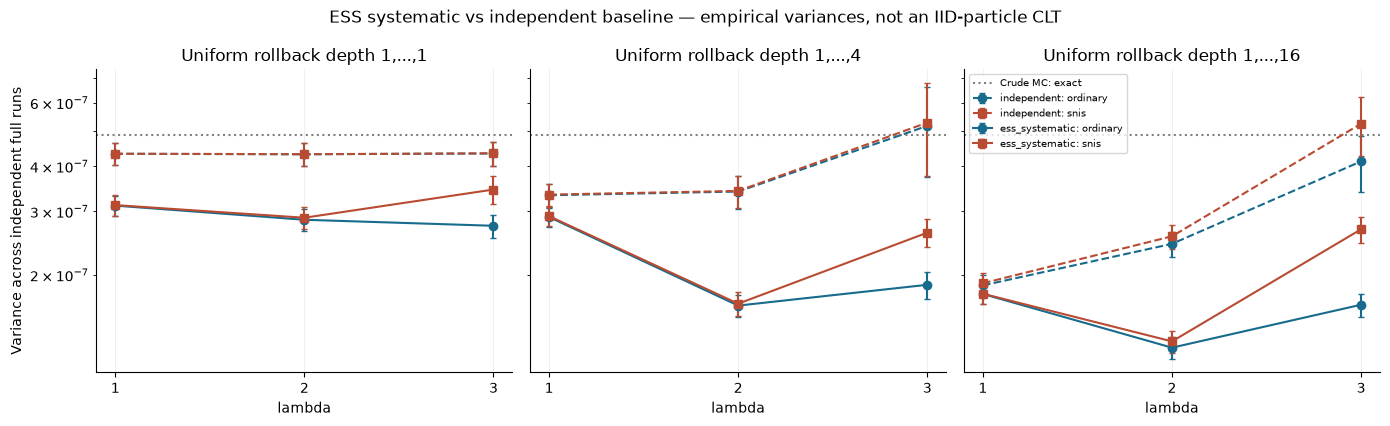

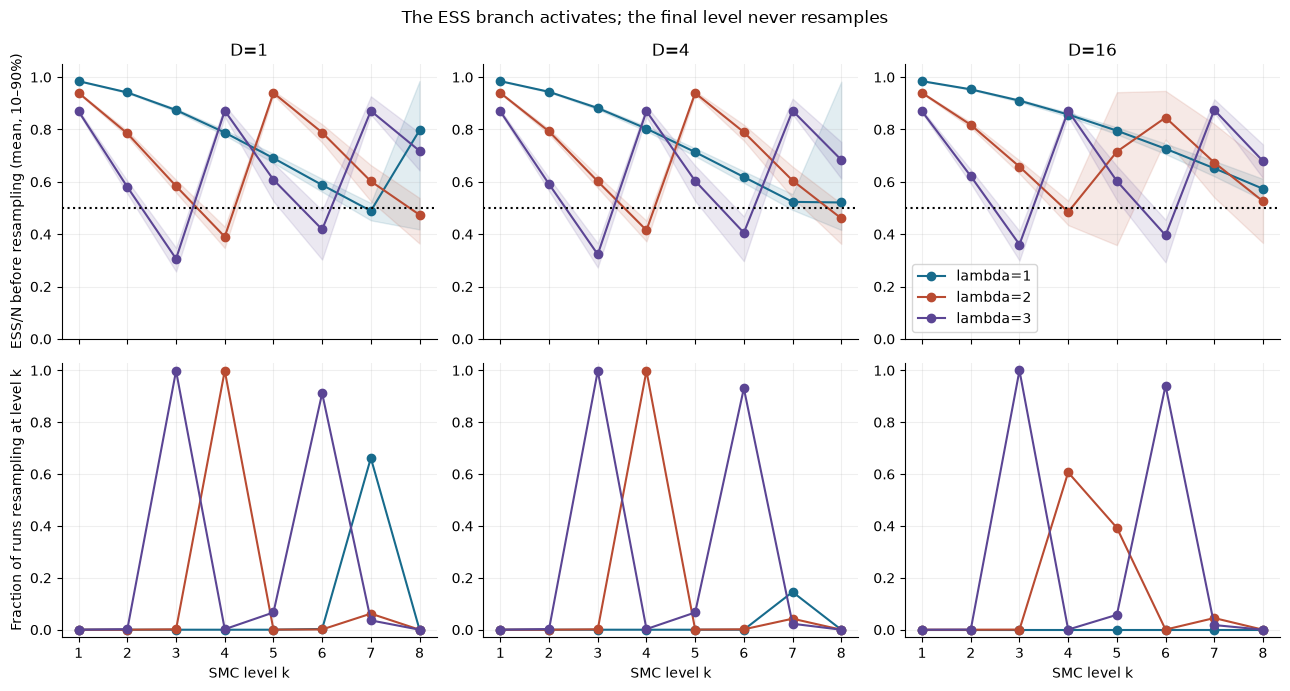

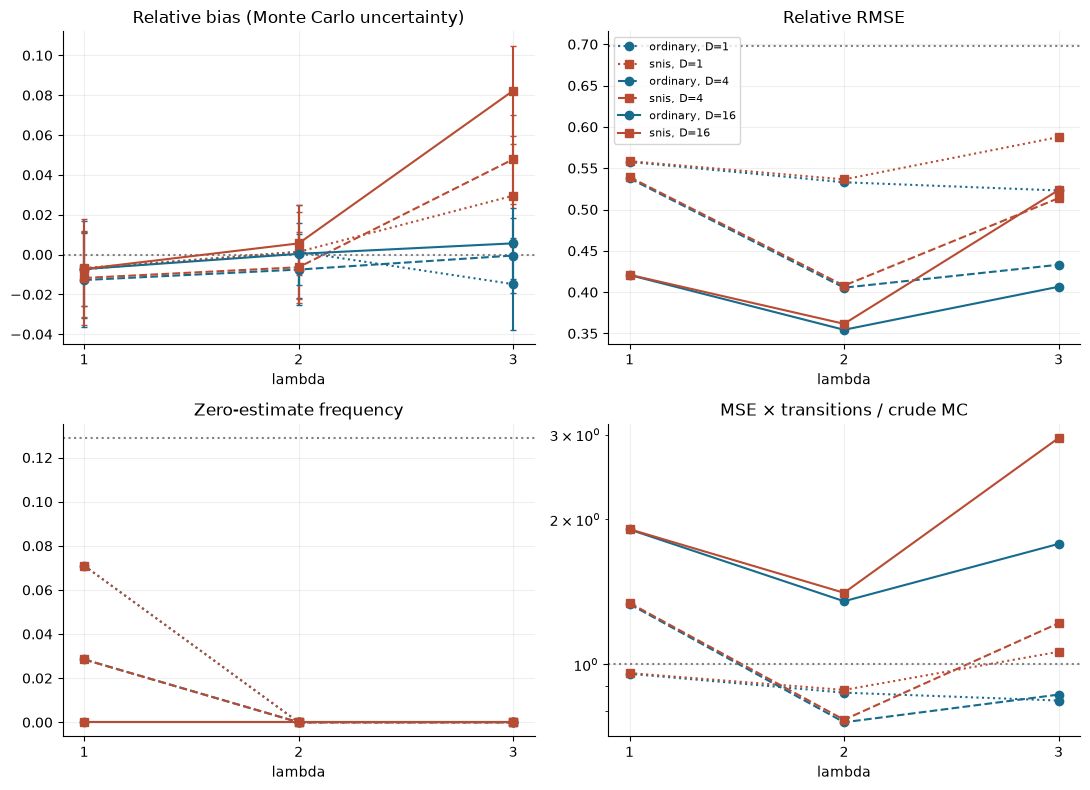

In [10]:
create_figures(frame, summary, manifest, output_dir=OUTPUT_DIR)

## Identità del normalizzatore e sintesi dei risultati

In [11]:
comparison = write_report(frame, summary, manifest, output_dir=OUTPUT_DIR)
display(comparison)
display(summary.query("policy == 'ess_systematic' and estimator == 'ordinary'")[['lambda', 'D', 'mean_z_hat', 'z_hat_mc_se', 'true_z', 'mean_reverse_mass', 'reverse_mass_mc_se']])
best = summary.query("policy == 'ess_systematic' and `lambda` > 0").sort_values('rmse').iloc[0]
display(Markdown(f"**Minimo RMSE osservato nella griglia:** lambda={best['lambda']:g}, D={best['D']:g}, {best['estimator']}, RMSE={best['rmse']:.6g}. MSE × transizioni / crude MC = {best['mse_times_cost_relative_mc']:.3f}. La selezione è descrittiva, non una prova di ottimalità."))
display(Markdown(f"Resampling attivato in **{manifest['active_resampling_runs']} run**; escluso in tutte le run al livello finale. Il file RISULTATI.md contiene tutte le tabelle e la discussione dei limiti teorici."))


,lambda,D,policy,estimator,bias,bias_mc_se,variance,rmse,zero_frequency
0,0,0,crude,ordinary,1.757813e-05,0.000016,4.894663e-07,0.000700,0.128
33,2,16,ess_systematic,ordinary,3.683732e-07,0.000008,1.257063e-07,0.000354,0.000
34,2,16,ess_systematic,snis,5.613761e-06,0.000008,1.308411e-07,0.000362,0.000
35,2,16,independent,ordinary,1.011948e-05,0.000011,2.437425e-07,0.000494,0.000
36,2,16,independent,snis,1.962478e-05,0.000011,2.557796e-07,0.000506,0.000


,lambda,D,mean_z_hat,z_hat_mc_se,true_z,mean_reverse_mass,reverse_mass_mc_se
1,0,16,1.000000,0.000000,1.000000,1.000000,0.000000
5,1,1,1.647823,0.000999,1.648721,0.999813,0.000331
9,2,1,7.391783,0.024321,7.389056,1.001838,0.001033
13,3,1,88.376592,2.087997,90.017131,0.994455,0.005067
17,1,4,1.648242,0.000930,1.648721,0.999655,0.000294
21,2,4,7.388033,0.020213,7.389056,1.000432,0.000972
25,3,4,90.820254,1.666883,90.017131,1.003695,0.006414
29,1,16,1.647852,0.000708,1.648721,1.000378,0.000545
33,2,16,7.391121,0.017811,7.389056,0.999212,0.001704
37,3,16,88.989017,1.266958,90.017131,0.996935,0.007642


**Minimo RMSE osservato nella griglia:** lambda=2, D=16, ordinary, RMSE=0.000354462. MSE × transizioni / crude MC = 1.352. La selezione è descrittiva, non una prova di ottimalità.

Resampling attivato in **13621 run**; escluso in tutte le run al livello finale. Il file RISULTATI.md contiene tutte le tabelle e la discussione dei limiti teorici.

## Esportazione

L'archivio contiene CSV completi, manifest, report e grafici. In Colab si può scaricarlo dal pannello Files. Il notebook resta autonomo anche senza questo archivio: Run all rigenera ogni risultato.

In [12]:
import zipfile
from pathlib import Path
output_path = Path(OUTPUT_DIR)
(output_path / 'test_results.json').write_text(json.dumps({'passed': passed_checks, 'count': len(passed_checks)}, indent=2), encoding='utf-8')
archive_path = Path('rollback_smc_results.zip')
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(output_path.iterdir()):
        if path.is_file():
            archive.write(path, arcname=path.name)
display(FileLink(str(archive_path)))
print('Run all completato: test, esperimenti, tabelle, grafici e archivio generati.')


C:\Users\UTENTE\AppData\Local\Temp\rollback_notebook_rw9stkmz\empty_working_directory\rollback_smc_results.zip

Run all completato: test, esperimenti, tabelle, grafici e archivio generati.
